In [1]:
!pip install jupyter ipykernel numpy pandas matplotlib tqdm vector tables scipy

#ipykernel: bridge between jupyter nb and python *essential for running python in jupyter nb
#numpy: python library for working with arrays, for linear algebra, fourier tranform, and matrices
#pandas: allows for handling of data, merging, joining datasets, inserting and deleting columns from DataFrames
#matplotlib: library for creating static, animaed, and interactice visualizations in python, line plots, bar charts, histograms, scatter plots, and 3D vis
#tqdm: provides extensible progress bars for loops and iterables --> visualize progress of time consuming tasks
#vector: python library for 2D and 3D spatial vectors, (even 4D). INTENDED FOR PERFRMING GEOMTRIC CALCS. ON ARRAYS OF VECTORS
#tables: storing and reading large arrays, tables, and nested data structures
#scipy: builds on capabilities of numpy and provides additional functionality

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
import pickle
from collections import OrderedDict #helps to remember order of key insertions
import sys
plot_dir = "OmniFold"

In [3]:

# Update the file path to your local file
local_file_path = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\multifold.h5"

multifold_util = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py"

if os.path.isfile(local_file_path):
    print("Skipping download -- data already exists locally.")
else:
    print("File not found at the specified path.")

try:
    sys.path.append(os.path.dirname(multifold_util)) #adds multifold_util to list of directories that python searches for modules
    from multifold_util import *
    import numpy as np
    import pandas as pd
    pd.options.mode.chained_assignment = None
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    import os
    import pickle

    if os.path.isfile(multifold_util):
        print("Done!")
    else:
        raise Exception("File does not exist.")

except Exception as e:
    print(f"There was an error: {e}")

Skipping download -- data already exists locally.
Done!


In [4]:
n_events = None

In [5]:
print("Loading the measurement - based on actual data")

multifold = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\multifold.h5", stop = n_events)
# Measurement of data using alternative MC samples. 
multifold_sherpa = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\multifold_sherpa.h5", stop =n_events) # the 0.8 is to make the nEff approximately equal to the ratio in the full measurement
multifold_nonDY  = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\multifold_nonDY.h5", stop = n_events)
mc_preds = np.load(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\mc_preds.npy", allow_pickle=True)

Loading the measurement - based on actual data


In [6]:
### Construct masks for track pT cuts
mask_trackj1 = np.array(multifold['pT_trackj1'] > 5, dtype='bool')
mask_trackj2 = np.array(multifold['pT_trackj2'] > 5, dtype='bool')

mask_sherpa_trackj1 = np.array(multifold_sherpa['pT_trackj1'] > 5, dtype='bool')
mask_sherpa_trackj2 = np.array(multifold_sherpa['pT_trackj2'] > 5, dtype='bool')

mask_nonDY_trackj1 = np.array(multifold_nonDY['pT_trackj1'] > 5, dtype='bool')
mask_nonDY_trackj2 = np.array(multifold_nonDY['pT_trackj2'] > 5, dtype='bool')

In [7]:
bins_dict = ibu_bins # defined in demo_functions.py
# bins_dict['Ntracks_trackj1'] = [0.5, 2] # example of how to modify binning for a given variable

print(f"Loaded bins for {len(bins_dict)} observables:")
for obs, bins in bins_dict.items():
    print("{:>15} with {:2} bins [{:.1f} ... {:.1f}]".format(obs,len(bins),bins[0],bins[-1]))
    # print("  {}, {} bins: {}".format(obs,len(bins),bins))

Loaded bins for 24 observables:
          pT_l1 with  7 bins [25.0 ... 800.0]
          pT_l2 with  7 bins [25.0 ... 400.0]
         eta_l1 with 15 bins [-2.5 ... 2.5]
         eta_l2 with 15 bins [-2.5 ... 2.5]
         phi_l1 with 17 bins [-3.1 ... 3.1]
         phi_l2 with 17 bins [-3.1 ... 3.1]
     pT_trackj1 with  7 bins [5.0 ... 1000.0]
     pT_trackj2 with  5 bins [5.0 ... 500.0]
      y_trackj1 with 19 bins [-2.5 ... 2.5]
      y_trackj2 with 11 bins [-2.5 ... 2.5]
    phi_trackj1 with 17 bins [-3.1 ... 3.1]
    phi_trackj2 with 17 bins [-3.1 ... 3.1]
          pT_ll with  6 bins [200.0 ... 1000.0]
           y_ll with 15 bins [-2.5 ... 2.5]
Ntracks_trackj1 with  7 bins [0.5 ... 39.5]
Ntracks_trackj2 with  6 bins [0.5 ... 34.5]
      m_trackj1 with  7 bins [0.0 ... 70.0]
      m_trackj2 with  5 bins [0.0 ... 40.0]
   tau1_trackj1 with  8 bins [0.0 ... 0.9]
   tau1_trackj2 with  6 bins [0.0 ... 0.9]
   tau2_trackj1 with  8 bins [0.0 ... 0.5]
   tau2_trackj2 with  6 bins [0.0 ..

In [8]:
# List of systematic uncertainties, stored as weights in the dataset
event_systs     = [col for col in multifold.keys() if col.startswith("weights_muEff")] + ['weights_pileup']
theory_systs    = [col for col in multifold.keys() if col.startswith("weights_theory")]
track_systs     = [col for col in multifold.keys() if col.startswith("weights_track")]
muon_systs      = [col for col in multifold.keys() if col.startswith("weights_muCal")]

# List of stochastic uncertainty names
mc_stat_systs   = [col for col in multifold.keys() if col.startswith("weights_bootstrap_mc")]
data_stat_systs = [col for col in multifold.keys() if col.startswith("weights_bootstrap_data")]
ensemble_systs  = [col for col in multifold.keys() if col.startswith("weights_ensemble")]

In [9]:
uncertainties_filepath = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p"
force_recalculate = True
if os.path.exists(uncertainties_filepath) and not force_recalculate:
    print("Using pre-calculated uncertainties.") 
    uncertainties = np.load(uncertainties_filepath, allow_pickle=True)
else:
    print("Recalculating uncertainties from scratch.")
    uncertainties = {}

    for i in tqdm(range(24), desc="Unfolded vars"): # number of unfolded observables
        var = list(bins_dict.items())[i][0] #need list to create something indexable
        bins = np.array(list(bins_dict.items())[i][1])
        bin_centers = 0.5 * (bins[1:] + bins[:-1])

        if "trackj1" in var: 
            df = multifold[mask_trackj1]
            df_sherpa = multifold_sherpa[mask_sherpa_trackj1]
            df_nonDY = multifold_nonDY[mask_nonDY_trackj1]
        elif "trackj2" in var:
            df = multifold[mask_trackj2]
            df_sherpa = multifold_sherpa[mask_sherpa_trackj2]
            df_nonDY = multifold_nonDY[mask_nonDY_trackj2]
        else:
            df = multifold
            df_sherpa = multifold_sherpa
            df_nonDY = multifold_nonDY
            
        nom, _ = np.histogram(df[var], bins=bins, weights=df.weights_nominal)    

        final_event          = calculate_uncertainty(df, var, bins, event_systs)
        final_theory         = calculate_uncertainty(df, var, bins, theory_systs)
        final_track          = calculate_uncertainty(df, var, bins, track_systs)
        final_muon           = calculate_uncertainty(df, var, bins, muon_systs)
        final_mc_stat        = calculate_stat_uncertainty(df, var, bins, mc_stat_systs)
        final_data_stat      = calculate_stat_uncertainty(df, var, bins, data_stat_systs)
        final_nn_init        = calculate_stat_uncertainty(df, var, bins, ensemble_systs)/np.sqrt(len(ensemble_systs))
        
        ### Unfolding (DD)
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_dd)
        target_dd, _ = np.histogram(df[var], bins=bins, weights=df.target_dd)
        final_unfolding_dd = 100*np.sqrt((syst-target_dd)**2)/target_dd

        ### Unfolding (HV)
        syst, _ = np.histogram(df_sherpa[var], bins=bins, weights=df_sherpa.weights_nominal)
        smoothed_hv_syst_signed = smooth_uncertainty(syst-nom, bin_centers)
        final_unfolding_hv = 100*np.sqrt((smoothed_hv_syst_signed)**2)/nom

        ### Sum these together in quadrature
        final_unfolding = np.sqrt(final_unfolding_hv**2 + final_unfolding_dd**2)

        ### Luminosity 
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_lumi)
        final_lumi = 100*np.sqrt((syst-nom)**2)/nom

        ### Top Background 
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_topBackground)
        final_top = 100*np.sqrt((syst-nom)**2)/nom

        ### Non-Strong Background
        syst, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weights_nominal)
        final_nonDY = 100*np.sqrt((syst-nom)**2)/nom

        final_exp = np.sqrt(final_lumi**2 + final_muon**2 + final_track**2 + final_event**2)
        uncertainties[var+"_exp"] = final_exp
        uncertainties[var+"_theory"] = final_theory
        uncertainties[var+"_mc_stat"] = np.sqrt(final_mc_stat**2 + final_nn_init**2)
        uncertainties[var+"_data_stat"] = final_data_stat
        uncertainties[var+"_unfolding"] = final_unfolding
        uncertainties[var+"_top"] = final_top
        uncertainties[var+"_nonDY"] = final_nonDY

        total = np.sqrt(
            + final_theory**2 
            + final_exp**2
            + final_mc_stat**2
            + final_data_stat**2
            + final_unfolding**2
            + final_top**2
            + final_nonDY**2
        )
        uncertainties[var+"_total"] = total

        print(f"Saving calculated uncertainties to folder: {uncertainties_filepath}")
        with open(uncertainties_filepath, "wb") as f:
            pickle.dump(uncertainties, f)
        print("Done")

Recalculating uncertainties from scratch.


Unfolded vars:   4%|▍         | 1/24 [00:08<03:21,  8.75s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p
Done


Unfolded vars:   8%|▊         | 2/24 [00:16<03:05,  8.45s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p
Done


...

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p
Done


Unfolded vars:  96%|█████████▌| 23/24 [03:22<00:09,  9.18s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p
Done


Unfolded vars: 100%|██████████| 24/24 [03:32<00:00,  8.84s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\data_uncertainties.p
Done


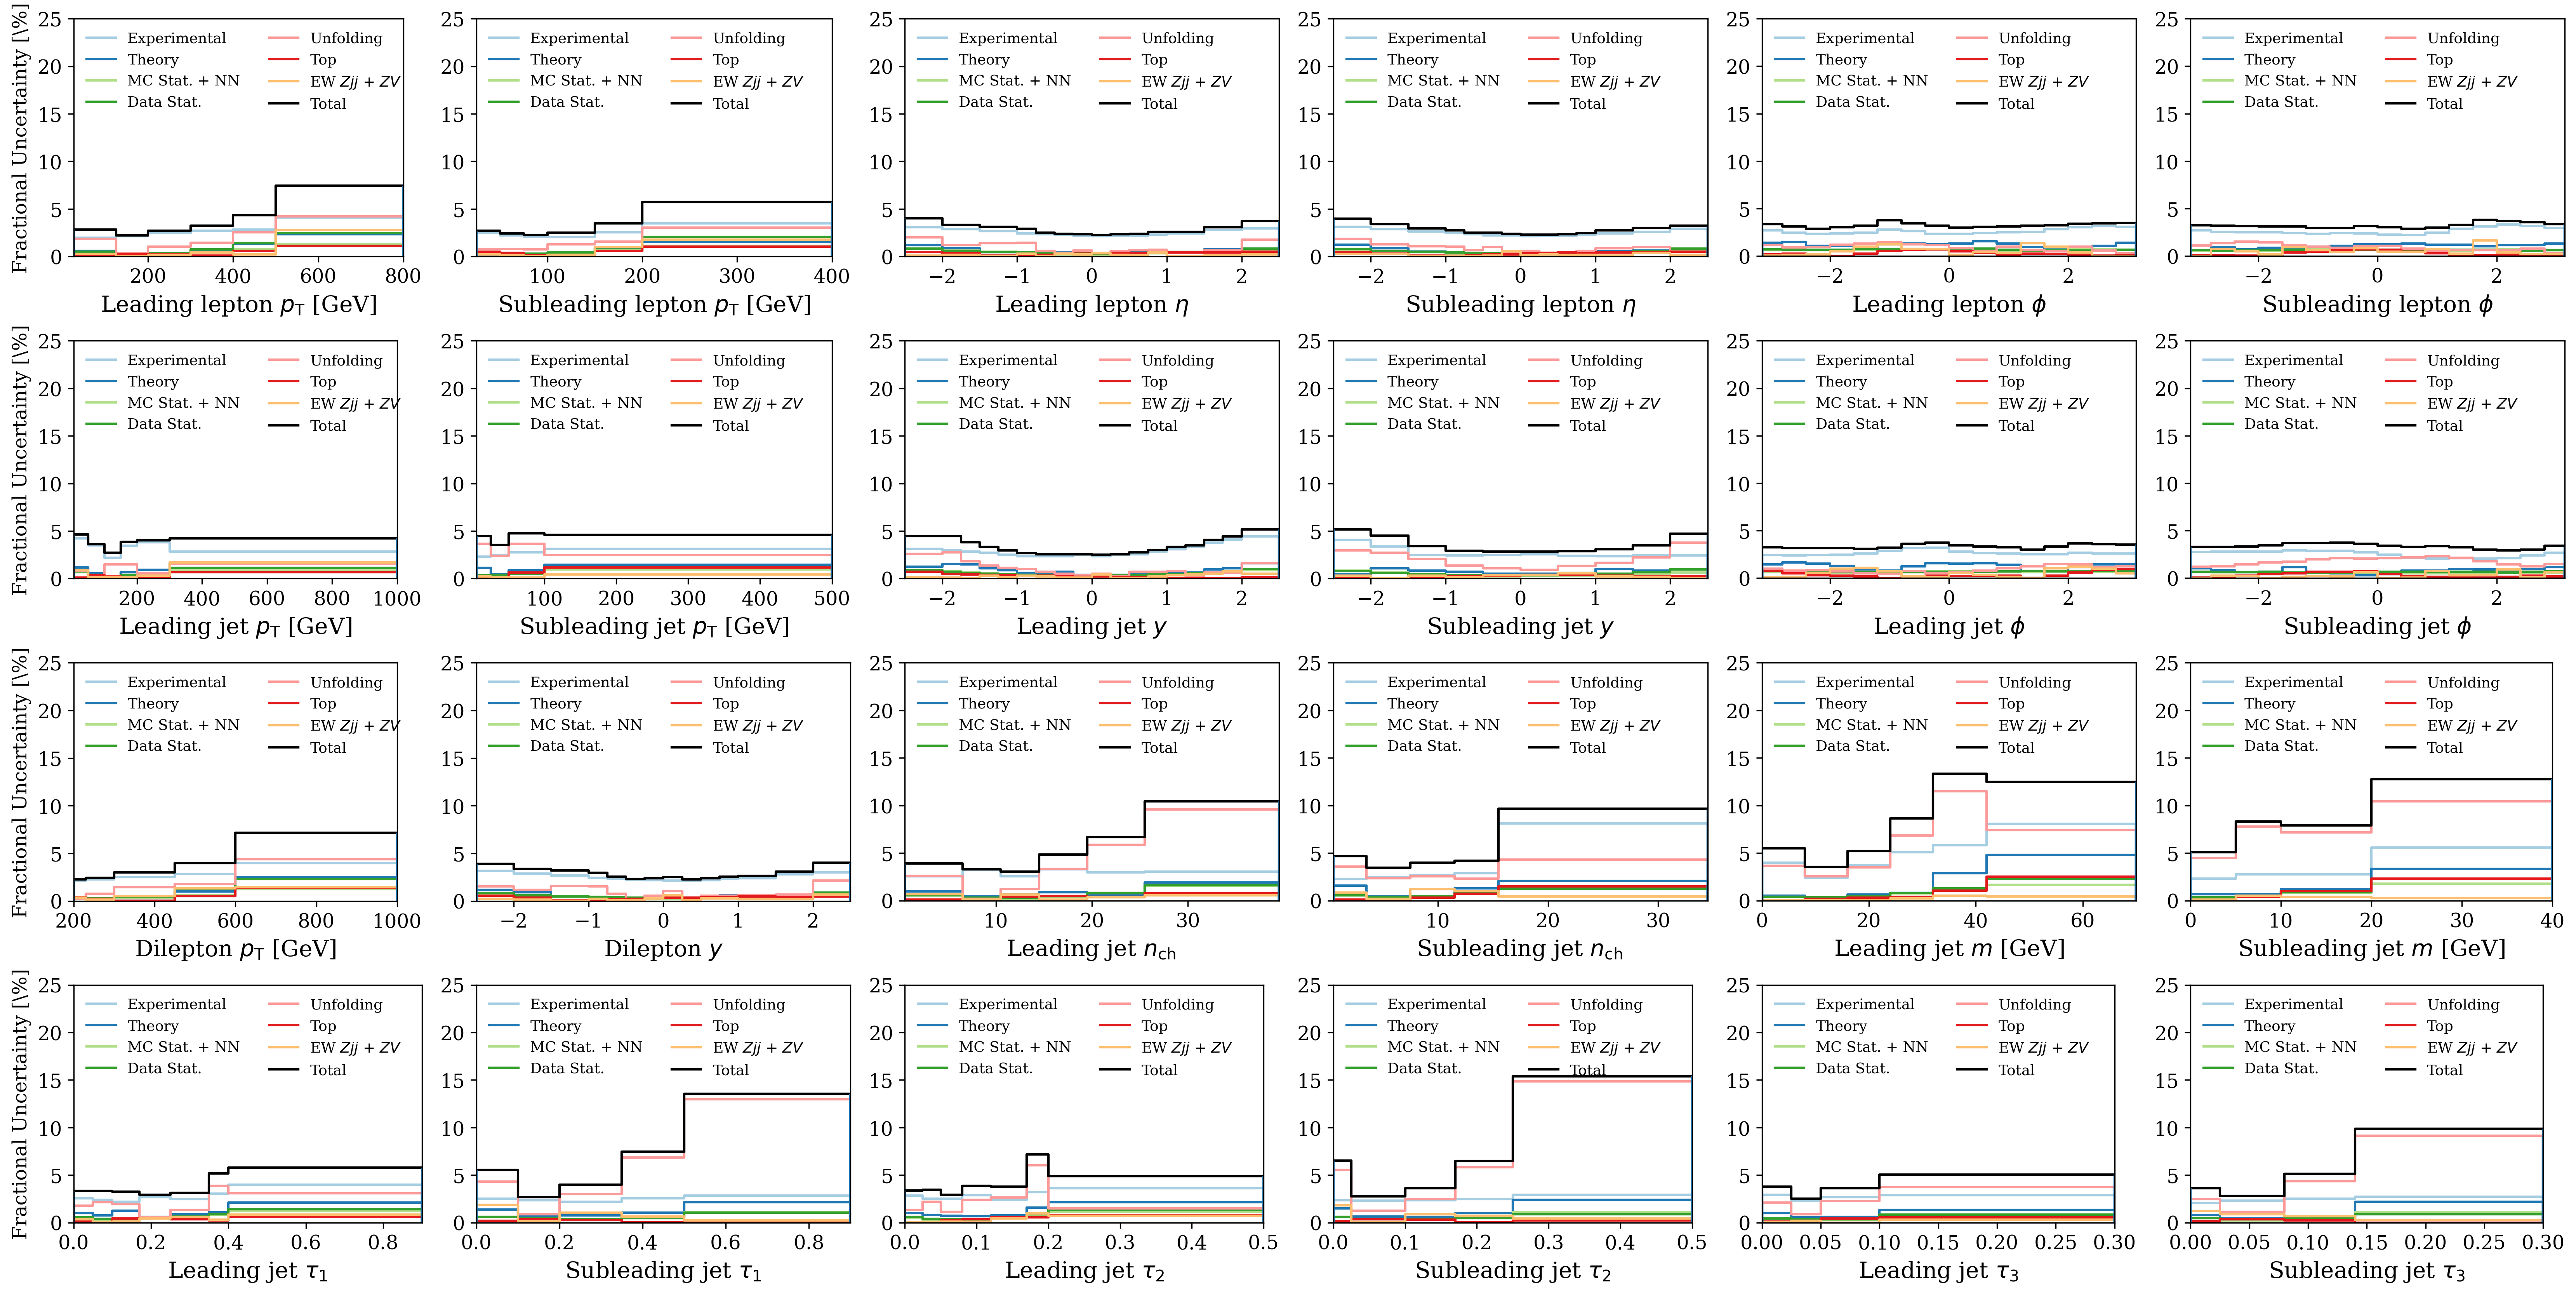

In [10]:
import matplotlib
matplotlib.rcParams['text.usetex'] = False
fig = plt.figure(figsize=(22,11), dpi=300, constrained_layout=True)
subfigs = fig.subfigures(4, 6)

for i, subfig in enumerate(subfigs.flat):
    ax = subfig.subplots(1, 1)
    colors = [plt.cm.Paired(i) for i in range(20)]
    var = list(bins_dict.items())[i][0]
    bins = np.array(list(bins_dict.items())[i][1])

    ax.step(bins, np.concatenate([[uncertainties[var+'_exp'][0]],uncertainties[var+'_exp']]),              label = "Experimental",       color=colors[0],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_theory'][0]],uncertainties[var+'_theory']]),        label = "Theory",             color=colors[1],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_mc_stat'][0]],uncertainties[var+'_mc_stat']]),      label = "MC Stat. + NN",      color=colors[2],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_data_stat'][0]],uncertainties[var+'_data_stat']]),  label = "Data Stat.",         color=colors[3],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_unfolding'][0]],uncertainties[var+'_unfolding']]),  label = "Unfolding",          color=colors[4]     )
    ax.step(bins, np.concatenate([[uncertainties[var+'_top'][0]],uncertainties[var+'_top']]),              label = "Top",                color=colors[5],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_nonDY'][0]],uncertainties[var+'_nonDY']]),          label = r"EW $Zjj$ + $ZV$",   color=colors[6],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_total'][0]],uncertainties[var+'_total']]),          label = "Total",              color='black',      )

    ### draw lines at the beginning and end of the first and last bins, for plotting purposes
    label_list = ['exp', 'theory', 'mc_stat', 'data_stat', 'unfolding', 'top', 'nonDY', 'total']
    for label in label_list:
        plt.vlines(x=bins[0], ymin=0, ymax=uncertainties[var+'_'+label][0])
        plt.vlines(x=bins[-1], ymin=0, ymax=uncertainties[var+'_'+label][-1])

    ax.xaxis.set_tick_params(labelsize=12)
    ax.yaxis.set_tick_params(labelsize=12)
    if i % 6 == 0: ax.set_ylabel(r"Fractional Uncertainty [\%]", fontsize=12)
    ax.legend(fontsize=9, loc='upper left', ncol=2, frameon=False)
    ax.set_xlim([bins[0], bins[-1]])
    ax.set_ylim([0, 25])
    ax.set_xlabel(plot_labels[var], fontsize=14);

plt.savefig(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\uncertainties")

Plots: 100%|██████████| 24/24 [00:16<00:00,  1.45it/s]


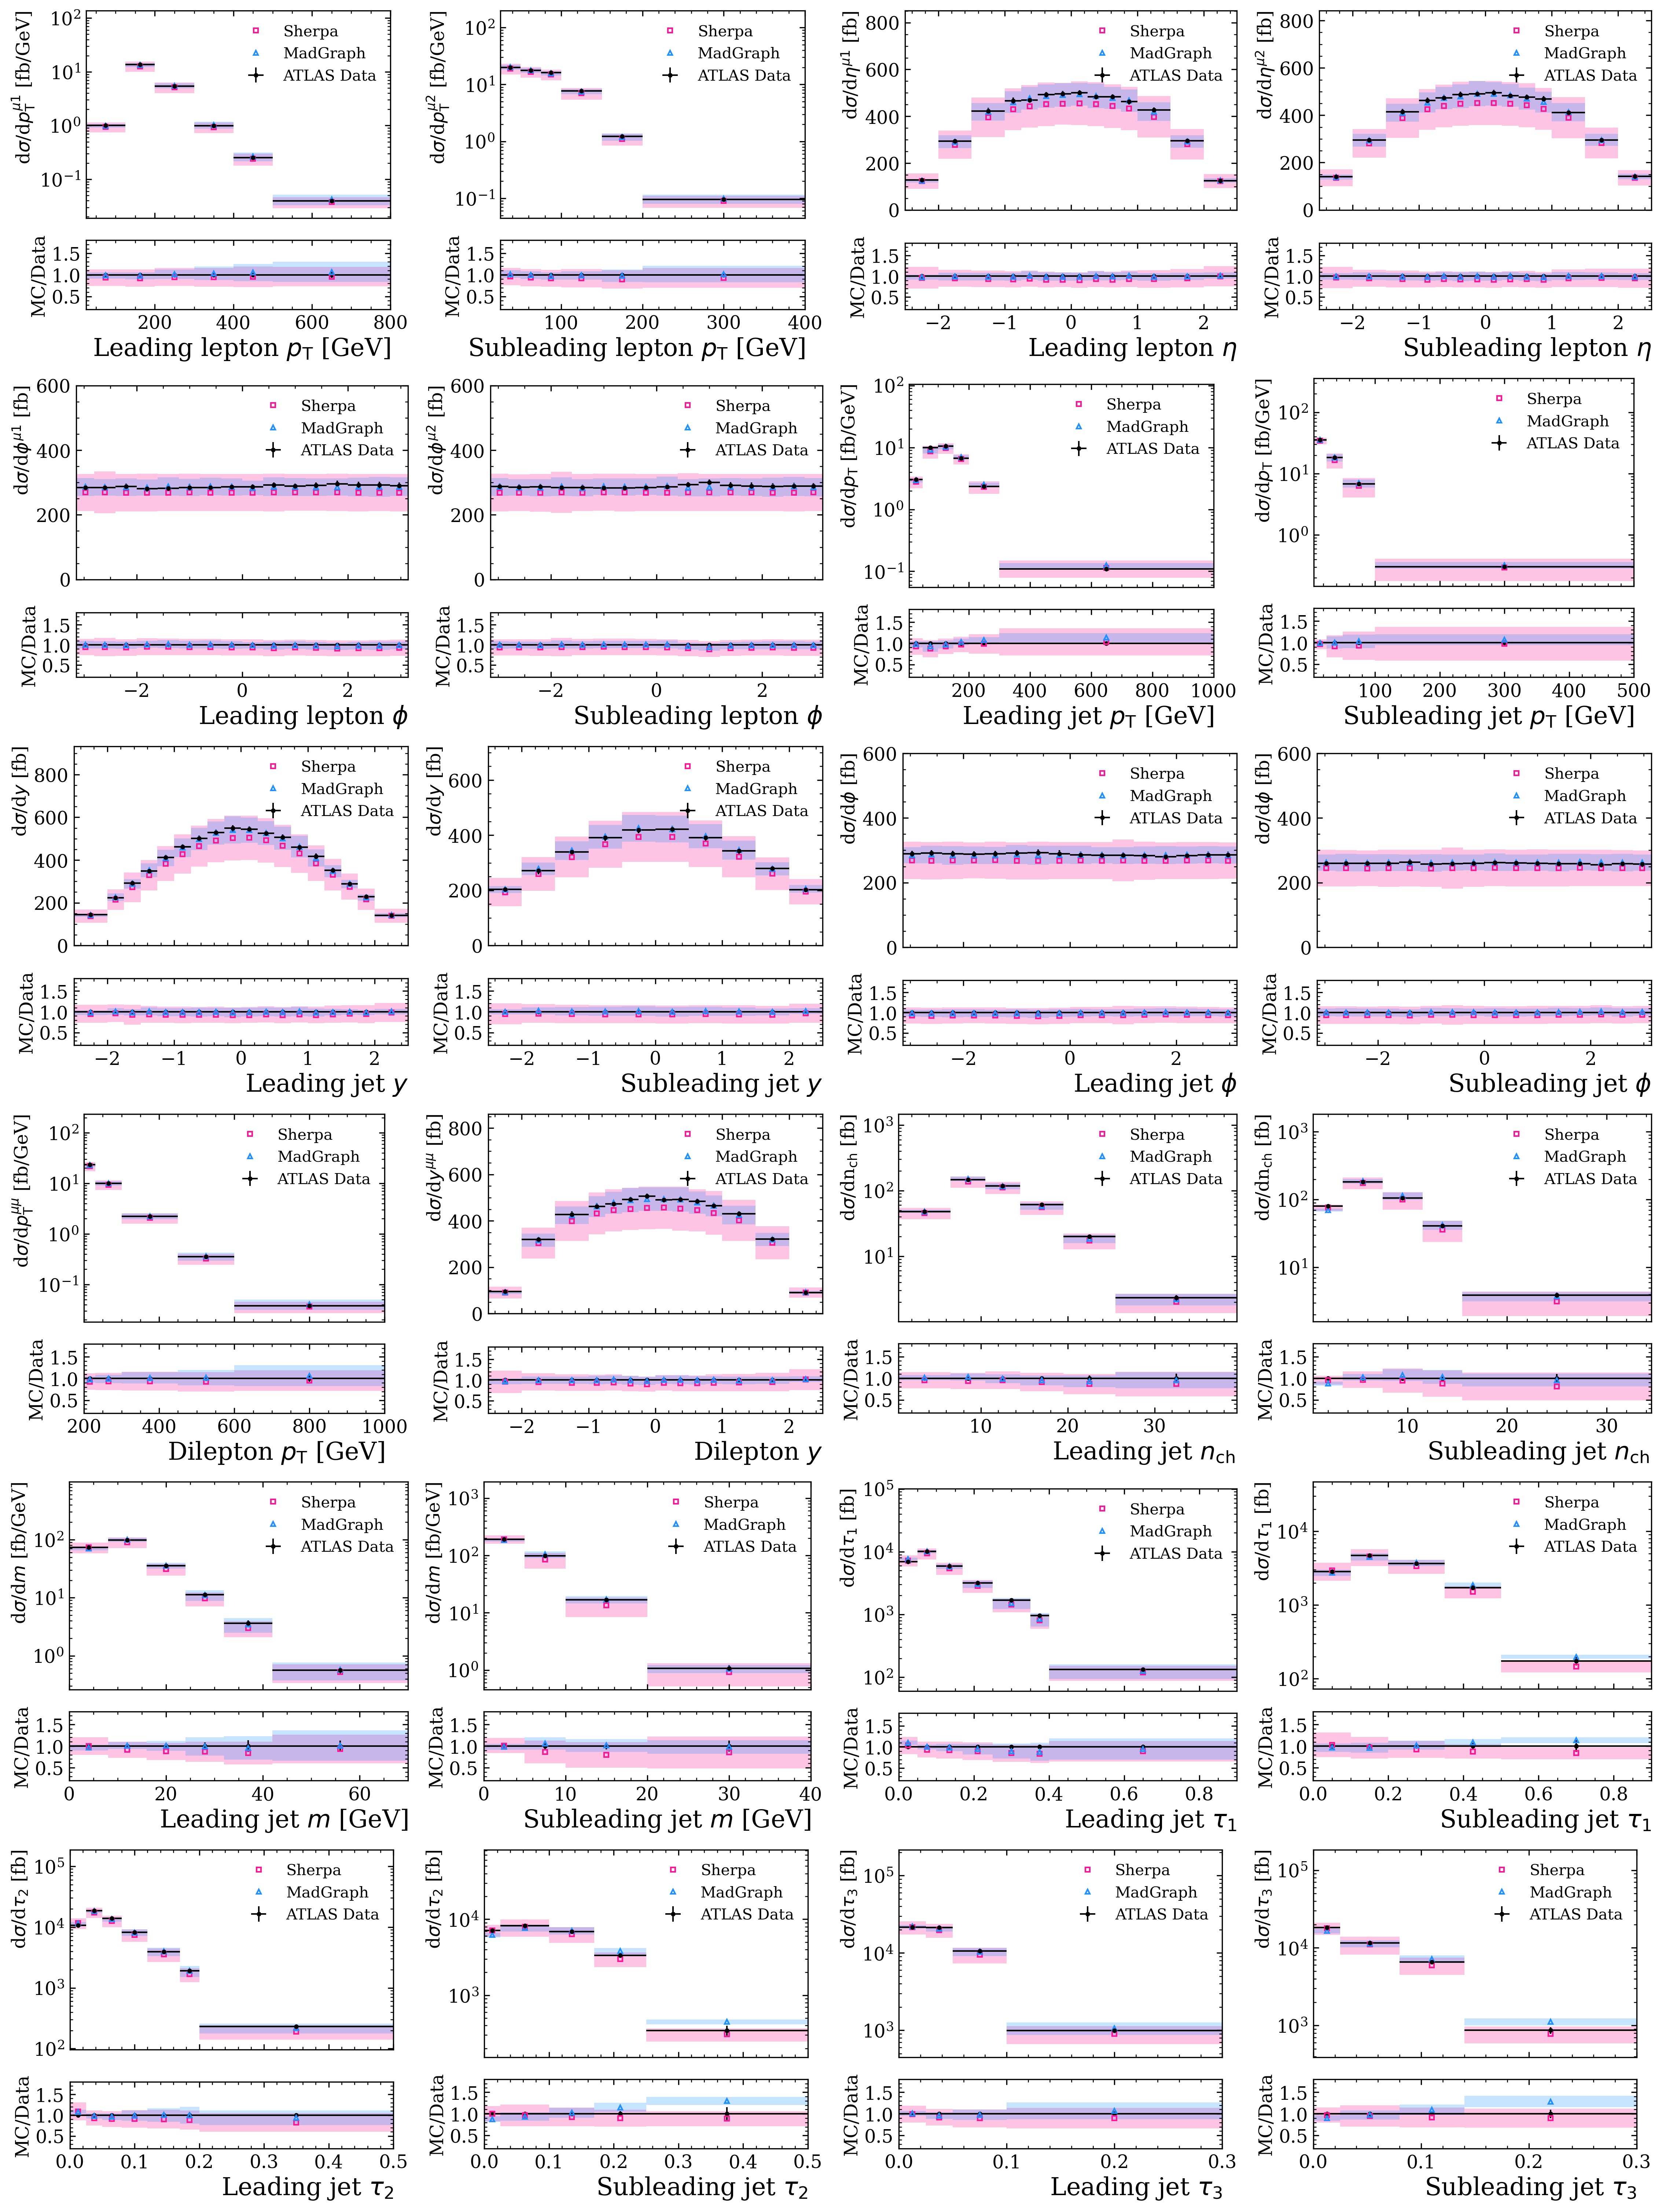

In [11]:
fig = plt.figure(figsize=(15,20), dpi=300, constrained_layout=True)
subfigs = fig.subfigures(6, 4)

for i, subfig in enumerate(tqdm(subfigs.flat, desc="Plots")):  
    axs = subfig.subplots(2, 1, sharex=True, sharey=False, gridspec_kw = {'height_ratios':[3, 1]})
    var = list(bins_dict.items())[i][0]
    bins = np.array(list(bins_dict.items())[i][1])
    bin_centers = 0.5 * (bins[1:] + bins[:-1])
    bin_widths = np.array([bins[n+1] - bins[n] for n in range(len(bins)-1)])
    
    if "trackj1" in var: 
        df = multifold[mask_trackj1]
    elif "trackj2" in var:
        df = multifold[mask_trackj2]
    else:
        df = multifold    
    
    ### Sherpa
    counts = mc_preds[i]['sherpa_counts']
    sherpa_density = counts/lumi/bin_widths
    sherpa_error = mc_preds[i]['sherpa_err']/mc_preds[i]['sherpa_counts']
    _ = make_error_boxes(axs[0], bin_centers, sherpa_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([sherpa_density*sherpa_error, sherpa_density*sherpa_error]), facecolor='deeppink', alpha=0.25, marker="s", label=r'Sherpa',)
    
    ### MGFxFx 
    counts = mc_preds[i]['mgfxfx_counts']
    mgfxfx_density = counts/lumi/bin_widths
    mgfxfx_error = mc_preds[i]['mgfxfx_err']/mc_preds[i]['mgfxfx_counts']
    _ = make_error_boxes(axs[0], bin_centers, mgfxfx_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([mgfxfx_density*mgfxfx_error, mgfxfx_density*mgfxfx_error]), facecolor='dodgerblue', alpha=0.25, marker="^", label=r'MadGraph')

    ### MultiFold
    multifold_density, _, _ = axs[0].hist(df[var], weights=df.weights_nominal, bins=bins, color='black', linewidth= 2, density=True, alpha=0)
    multifold_density *= np.sum(df.weights_nominal)
    
    axs[0].minorticks_on()
    axs[1].minorticks_on()
    axs[0].xaxis.set_tick_params(labelsize=12, which='both', direction='in', top=True)
    axs[0].yaxis.set_tick_params(labelsize=12, which='both', direction='in', right=True)
    axs[0].set_ylabel(labels[var], fontsize=12, labelpad=2, loc='top')
    axs[0].set_ylim([0, 1.7 * max(max(mgfxfx_density), max(multifold_density))])
    
    ### Set some plots to use log y scale
    if 'phi' not in var and 'eta' not in var and 'y' not in var:
        axs[0].set_yscale('log')
        axs[0].set_ylim([0.5*min(min(sherpa_density), min(multifold_density)), 10 * max(max(sherpa_density), max(multifold_density))])
    
    elif 'phi' in var:
        axs[0].set_ylim(0,600)

    axs[0].errorbar(bin_centers, multifold_density, xerr=bin_widths/2, yerr=multifold_density*uncertainties[var+"_total"]/100, marker=".", linestyle="None", color="k", alpha=1, ecolor='k', label="ATLAS Data", markersize=4, linewidth=1)
    axs[0].legend(fontsize=10, frameon=False, loc='best');
    axs[1].errorbar(bin_centers, np.ones(len(bin_centers)), xerr=bin_widths/2, yerr=uncertainties[var+"_total"]/100, marker=".", linestyle="None", color="k", alpha=1,  ecolor='k', label="ATLAS Data", markersize=4, linewidth=1)
    _ = make_error_boxes(axs[1], bin_centers, sherpa_density/multifold_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([(sherpa_density/multifold_density)*sherpa_error, (sherpa_density/multifold_density)*sherpa_error]), facecolor='deeppink', alpha=0.25, marker="s", label=r'Sherpa')
    _ = make_error_boxes(axs[1], bin_centers, mgfxfx_density/multifold_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([(mgfxfx_density/multifold_density)*mgfxfx_error, (mgfxfx_density/multifold_density)*mgfxfx_error]), facecolor='dodgerblue', alpha=0.25, marker="^", label=r'MadGraph')
    axs[1].set_xlim(bins[0], bins[-1])
    axs[1].set_ylim([0.2,1.8])
    axs[1].xaxis.set_tick_params(labelsize=12, which='both', direction='in', top=True)
    axs[1].yaxis.set_tick_params(labelsize=12, which='both', direction='in', right=True)
    axs[1].set_ylabel('MC/Data', fontsize=12, labelpad=2, loc='center')
    axs[1].set_xlabel(plot_labels[var], fontsize=16, labelpad=2, loc='right');
    
plt.savefig(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data\xsec")

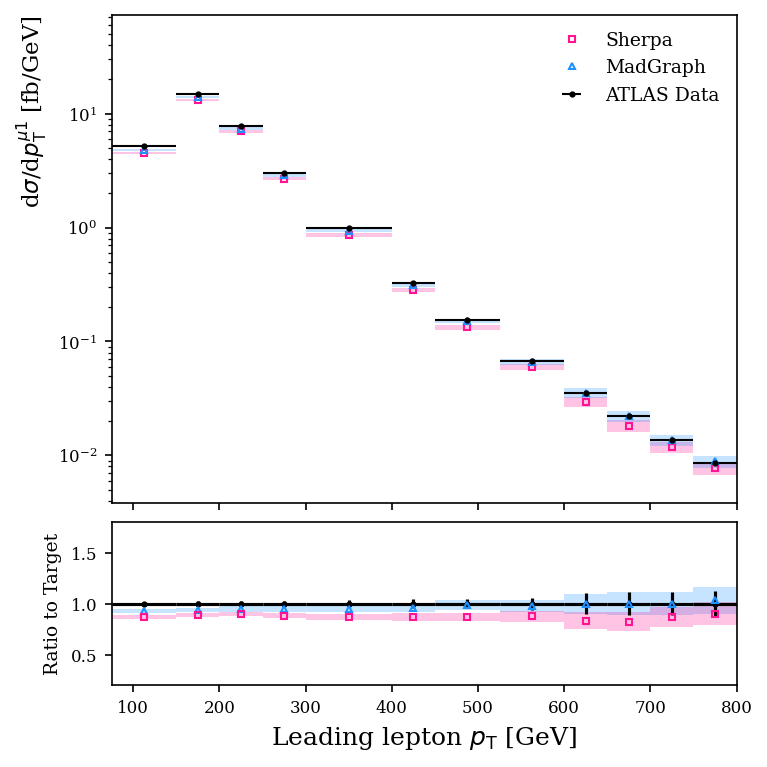

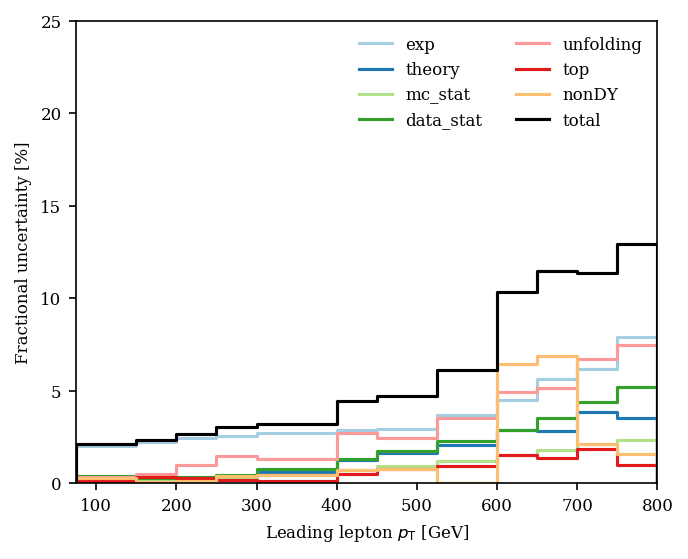

In [14]:
#SAVING THIS CODE HERE IN CASE

main_path = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\data"


#Add statement that notifies when a bin has less than 5000 events, statistical uncertainty should be under 15%
#change from matplotlib code to np code
### Plot Ntracks_trackj1 with custom bins using weight_mc (no mc_preds needed)

#adding in quadrature accounts for the fact that each source of uncertainy is an independent random error, that don't all propagate in the same direction
uncertainties = {
    "exp": final_exp,
    "theory": final_theory,
    "mc_stat": np.sqrt(final_mc_stat**2 + final_nn_init**2),
    "data_stat": final_data_stat,
    "unfolding": final_unfolding,
    "top": final_top,
    "nonDY": final_nonDY,
}

uncertainties["total"] = np.sqrt(
    uncertainties["exp"]**2
    + uncertainties["theory"]**2
    + uncertainties["mc_stat"]**2
    + uncertainties["data_stat"]**2
    + uncertainties["unfolding"]**2
    + uncertainties["top"]**2
    + uncertainties["nonDY"]**2
)


def custom_binning(var, binslist):
    lumi = 138.96
    bins = np.array(binslist)
    bin_centers = 0.5 * (bins[1:] + bins[:-1])
    bin_widths  = np.diff(bins)

    fig, axs = plt.subplots(2, 1, sharex=True, figsize=(5, 5), dpi=150,
                            gridspec_kw={'height_ratios': [3, 1]}, constrained_layout=True)
    
    if "trackj1" in var:
        df       = multifold[mask_trackj1]
        df_sherpa = multifold_sherpa[mask_sherpa_trackj1]
        df_nonDY  = multifold_nonDY[mask_nonDY_trackj1]
    elif "trackj2" in var:
        df        = multifold[mask_trackj2]
        df_sherpa = multifold_sherpa[mask_sherpa_trackj2]
        df_nonDY  = multifold_nonDY[mask_nonDY_trackj2]
    else:
        df        = multifold
        df_sherpa = multifold_sherpa
        df_nonDY  = multifold_nonDY

    nom, _ = np.histogram(df[var], bins=bins, weights=df.weights_nominal) #np.histogram returns counts and bin edges, so use _ because we defined bin_edges already
    final_event     = calculate_uncertainty(df, var, bins, event_systs)
    final_theory    = calculate_uncertainty(df, var, bins, theory_systs)
    final_track     = calculate_uncertainty(df, var, bins, track_systs)
    final_muon      = calculate_uncertainty(df, var, bins, muon_systs)
    final_mc_stat   = calculate_stat_uncertainty(df, var, bins, mc_stat_systs)
    final_data_stat = calculate_stat_uncertainty(df, var, bins, data_stat_systs)
    final_nn_init   = calculate_stat_uncertainty(df, var, bins, ensemble_systs) / np.sqrt(len(ensemble_systs))

     ### Unfolding (DD)
    syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_dd)
    target_dd, _ = np.histogram(df[var], bins=bins, weights=df.target_dd)
    final_unfolding_dd = 100*np.sqrt((syst-target_dd)**2)/target_dd

        ### Unfolding (HV)
    syst, _ = np.histogram(df_sherpa[var], bins=bins, weights=df_sherpa.weights_nominal)
    smoothed_hv_syst_signed = smooth_uncertainty(syst-nom, bin_centers)
    final_unfolding_hv = 100*np.sqrt((smoothed_hv_syst_signed)**2)/nom

    ### Sum these together in quadrature
    final_unfolding = np.sqrt(final_unfolding_hv**2 + final_unfolding_dd**2)

    ### Luminosity 
    syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_lumi)
    final_lumi = 100*np.sqrt((syst-nom)**2)/nom

    ### Top Background 
    syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_topBackground)
    final_top = 100*np.sqrt((syst-nom)**2)/nom

    ### Non-Strong Background
    syst, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weights_nominal)
    final_nonDY = 100*np.sqrt((syst-nom)**2)/nom

    final_exp = np.sqrt(final_lumi**2 + final_muon**2 + final_track**2 + final_event**2)
    total_unc = np.sqrt(final_theory**2 + final_exp**2 + final_mc_stat**2 +
                        final_data_stat**2 + final_unfolding**2 + final_top**2 + final_nonDY**2)
        
    # --- Starting distribution: DY + non-DY, exact equivalent of mc_preds at any binning ---
    dy_counts,       _ = np.histogram(df[var],       bins=bins, weights=df.weight_mc)
    nonDY_counts,    _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weight_mc)
    dy_counts_sq,    _ = np.histogram(df[var],       bins=bins, weights=df.weight_mc**2)
    nonDY_counts_sq, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weight_mc**2)
    total_counts    = dy_counts #+ nonDY_counts
    total_counts_sq = dy_counts_sq #+ nonDY_counts_sq
    #start_density = total_counts / bin_widths
    #start_error   = np.sqrt(total_counts_sq) / total_counts  # relative Poisson error

    #_ = make_error_boxes(axs[0], bin_centers, start_density,
     #                    np.vstack([bin_widths/2, bin_widths/2]),
      #                   np.vstack([start_density*start_error, start_density*start_error]),
       #                  facecolor='dodgerblue', alpha=0.25, marker="^", label='Start')
    
    
    ###Target density
    sherpa_counts, _ = np.histogram(multifold_sherpa[var], bins = bins, weights = multifold_sherpa.weight_mc)
    sherpa_density = sherpa_counts/bin_widths
    _ = make_error_boxes(axs[0], bin_centers, sherpa_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([sherpa_density*total_unc/100, sherpa_density*total_unc/100]), facecolor='deeppink', alpha=0.25, marker="s", label=r'Sherpa',)

    
    mg_counts, _ = np.histogram(multifold[var], bins = bins, weights = multifold.weight_mc)
    mg_density = mg_counts/bin_widths
    _ = make_error_boxes(axs[0], bin_centers, mg_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([mg_density*total_unc/100, mg_density*total_unc/100]), facecolor='dodgerblue', alpha=0.25, marker="^", label=r'MadGraph')
    ### Sherpa
    
   
    ### MultiFold
    multifold_density, _, _ = axs[0].hist(df[var], weights=df.weights_nominal, bins=bins, color='black', linewidth= 2, density=True, alpha=0)
    multifold_density *= np.sum(df.weights_nominal)
  
    axs[0].errorbar(bin_centers, multifold_density, xerr=bin_widths/2, yerr=None, marker=".",
                   linestyle="None", color="k", alpha = 1, ecolor= "k", label="ATLAS Data", markersize=4, linewidth=1)
    
    if 'phi' not in var and 'eta' not in var and 'y' not in var:
        axs[0].set_yscale('log')
        axs[0].set_ylim([0.5*min(min(multifold_density), min(sherpa_density)), 5 * max(max(multifold_density), max(sherpa_density))])
    axs[0].set_ylabel(labels[var], fontsize=11, loc='top') #might have to change ^ ylim
    axs[0].legend(fontsize=9, frameon=False)
    
    axs[1].errorbar(bin_centers, np.ones(len(bin_centers)), xerr=bin_widths/2,
                    yerr=total_unc/100, marker=".", linestyle="None", color="k", markersize=4)
    _ = make_error_boxes(axs[1], bin_centers, mg_density/multifold_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([mg_density/multifold_density*total_unc/100]*2),
                         facecolor='dodgerblue', alpha=0.25, marker="^", label='Start')
    _ = make_error_boxes(axs[1], bin_centers, sherpa_density/multifold_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([sherpa_density/multifold_density*total_unc/100]*2),
                         facecolor='deeppink', alpha=0.25, marker="s", label='ATLAS Pseudo-Data')
    axs[1].set_xlim(bins[0], bins[-1])
    axs[1].set_ylim([0.2, 1.8])
    axs[1].set_ylabel('Ratio to Target', fontsize=9)
    axs[1].set_xlabel(plot_labels[var], fontsize=12)

    plt.savefig(os.path.join(main_path, f"custom_binning_{var}"))
    plt.show()

    uncertainties = {
    "exp": final_exp,
    "theory": final_theory,
    "mc_stat": np.sqrt(final_mc_stat**2 + final_nn_init**2),
    "data_stat": final_data_stat,
    "unfolding": final_unfolding,
    "top": final_top,
        "nonDY": final_nonDY,
    }
    
    uncertainties["total"] = np.sqrt(
        uncertainties["exp"]**2
        + uncertainties["theory"]**2
        + uncertainties["mc_stat"]**2
        + uncertainties["data_stat"]**2
        + uncertainties["unfolding"]**2
        + uncertainties["top"]**2
        + uncertainties["nonDY"]**2
    )

    fig_unc, ax_unc = plt.subplots(figsize=(5,4), dpi=150)

    colors = plt.cm.Paired(range(8))
    
    for color, label in zip(colors,
                            ["exp","theory","mc_stat","data_stat",
                             "unfolding","top","nonDY","total"]):

        ax_unc.step(
            bins,
            np.r_[uncertainties[label][0], uncertainties[label]],
            where="pre",
            label=label,
            color="black" if label=="total" else color
        )
    
        ax_unc.vlines(bins[0], 0, uncertainties[label][0],
                      color="black" if label=="total" else color)
        ax_unc.vlines(bins[-1], 0, uncertainties[label][-1],
                      color="black" if label=="total" else color)
    
        ax_unc.set_xlim(bins[0], bins[-1])
        ax_unc.set_ylim(0, 25)
        ax_unc.set_ylabel("Fractional uncertainty [%]")
        ax_unc.set_xlabel(plot_labels[var])
        ax_unc.legend(frameon=False, fontsize=8, ncol=2)

    
    plt.savefig(os.path.join(main_path, f"uncertainties_{var}"))
    plt.show() #need to save fig before plotting so it doesn't save blank image

        

custom_binning("pT_l1", [75.0, 150.0, 200.0, 250.0, 300.0, 400.0, 450.0, 
                         525.0, 600.0, 650.0, 700.0, 750.0, 800.0])

In [25]:
def calculate_vars(df):
    df['j1tau21'] = df.tau2_trackj1/df.tau1_trackj1
    df["j1tau32"]= df.tau3_trackj1/df.tau2_trackj1

    def dR(v1, v2): #v1 and v2 are two arbitrary four vectors
        dy = v1.rapidity-v2.rapidity
        dphi = v1.deltaphi(v2)
        return np.sqrt(dy**2 + dphi**2)

    def dR_ll_trackj1(pT_l1, eta_l1, phi_l1, pT_l2, eta_l2, phi_l2, pT_trackj1, y_trackj1, phi_trackj1):

        #this returns dR between dilepton system and track jet.
        #need to establish 2 four vectors, one being dilepton system, one being j1 track.
        l1 = vector.array({
            "pt": pT_l1,
            "phi": phi_l1,
            "eta": eta_l1,
            "m": np.zeros_like(pT_l1) #returns array of zeroes with same shape as pT_l1
        })

        l2 = vector.array({
            "pt": pT_l2,
            "phi": phi_l2,
            "eta": eta_l2,
            "m":np.zeros_like(pT_l2)
        })
        track_j1 = vector.array({
            "pt": pT_trackj1,
            "phi": phi_trackj1,
            "eta": y_trackj1,
            "m":np.zeros_like(pT_trackj1)
        })

        ll = l1 + l2 #system is just sum of individual parts
        return dR(ll, track_j1)

    def dR_ll_trackj2(pT_l1, eta_l1, phi_l1, pT_l2, eta_l2, phi_l2, pT_trackj2, y_trackj2, phi_trackj2):
        l1 = vector.array({ "pt": pT_l1, "phi": phi_l1, "eta": eta_l1, "m":np.zeros_like(pT_l1)})
        l2 = vector.array({ "pt": pT_l2, "eta": eta_l2, "phi": phi_l2, "m": np.zeros_like(pT_l2)})

        track_j2 = vector.array({ "pt": pT_trackj2, "eta": y_trackj2, "phi": phi_trackj2, "m": np.zeros_like(pT_trackj2)})

        ll = l1 + l2

        return dR(ll, track_j2)

    def dphi_j1j2(phi_trackj1, phi_trackj2):
        dphi = np.abs(phi_trackj1 - phi_trackj2)
        return np.where(dphi > np.pi, 2 * np.pi - dphi, dphi)
        


    def phi_ll(pt_l1, eta_l1, phi_l1, pt_l2, eta_l2, phi_l2): 
            l1 = vector.array({"pt": pt_l1, "eta": eta_l1, "phi": phi_l1, "m": np.zeros(len(pt_l1))})
            l2 = vector.array({"pt": pt_l2, "eta": eta_l2, "phi": phi_l2, "m": np.zeros(len(pt_l2))})
            return l1.add(l2).phi
    
    df['phi_ll'] = phi_ll(np.array(df.pT_l1), np.array(df.eta_l1), np.array(df.phi_l1), 
                          np.array(df.pT_l2), np.array(df.eta_l2), np.array(df.phi_l2))
    df['dR_ll1'] = dR_ll_trackj1(
        np.array(df.pT_l1), np.array(df.eta_l1), np.array(df.phi_l1), 
        np.array(df.pT_l2), np.array(df.eta_l2), np.array(df.phi_l2),
        np.array(df.pT_trackj1), np.array(df.y_trackj1), np.array(df.phi_trackj1))
    df["dR_ll2"] = dR_ll_trackj2(np.array(df.pT_l1), np.array(df.eta_l1), np.array(df.phi_l1), 
                    np.array(df.pT_l2), np.array(df.eta_l2), np.array(df.phi_l2), 
                    np.array(df.pT_trackj2), np.array(df.y_trackj2), np.array(df.phi_trackj2))

    df["dphi_j1j2"] = dphi_j1j2(np.array(df.phi_trackj1), np.array(df.phi_trackj2))

    def m_ll(pT_l1, pT_l2, eta_l1, eta_l2, phi_l1, phi_l2):
        return (2*pT_l1*pT_l2*(np.cosh(eta_l1 - eta_l2)-np.cos(phi_l1-phi_l2)))**0.5

    df["m_ll"] = m_ll(np.array(df.pT_l1), np.array(df.pT_l2), np.array(df.eta_l1), np.array(df.eta_l2), np.array(df.phi_l1), np.array(df.phi_l2))
    
    
    return df

    
### Pick bins for each of these new variables
bins_dict['j1tau21'] = [0.0, 0.35, 0.51, 0.63, 0.71, 0.78, 1.0]
bins_dict["j1tau32"] = [0.0, 0.35, 0.51, 0.63, 0.71, 0.78, 1.0]
bins_dict['dR_ll1'] = [0.0, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.6, 4.0, 6.0]
bins_dict["dR_ll2"] = [0.0, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.6, 4.0, 6.0]
bins_dict["dphi_j1j2"] = [0.0, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.6, 4.0, 6.0]
#phi_ll was not plotted because it's not useful

### Define plot labels
plot_labels['j1tau21'] = r'Leading jet $\tau_2/\tau_1$'
plot_labels["j1tau32"] = r'Leading Jet $\tau_3/\tau_2$'
plot_labels['dR_ll1'] = r'$\Delta R(\ell\ell,j_1)$'
plot_labels["dR_ll2"] = r"$\Delta R(\ell\ell,j_2)$"
plot_labels["m_ll"] = r"Invariant Mass ll"
plot_labels["dphi_j1j2"] = r"$\Delta\phi(j_1,j_2)$"


labels['j1tau21'] = r'd$\sigma$/d$\tau_{21}$ [fb]'
labels["j1tau32"] = r'd$\sigma$/d$\tau_{32}$ [fb]'
labels['dR_ll1'] = r'd$\sigma$/d$\Delta R$ [fb]'
labels["dR_ll2"] = r"d$\sigma$/d$\Delta R$ [fb]"
labels["m_ll"] = r"d$\sigma$/d$m_{\ell\ell}$ [fb/GeV]"
labels["dphi_j1j2"] = r"d$\sigma$/d$\Delta\phi$ [fb]"

### Add these new variables to each dataset
for i, dataframe in enumerate([multifold, multifold_sherpa, multifold_nonDY]):
    [multifold, multifold_sherpa, multifold_nonDY][i] = calculate_vars(dataframe)


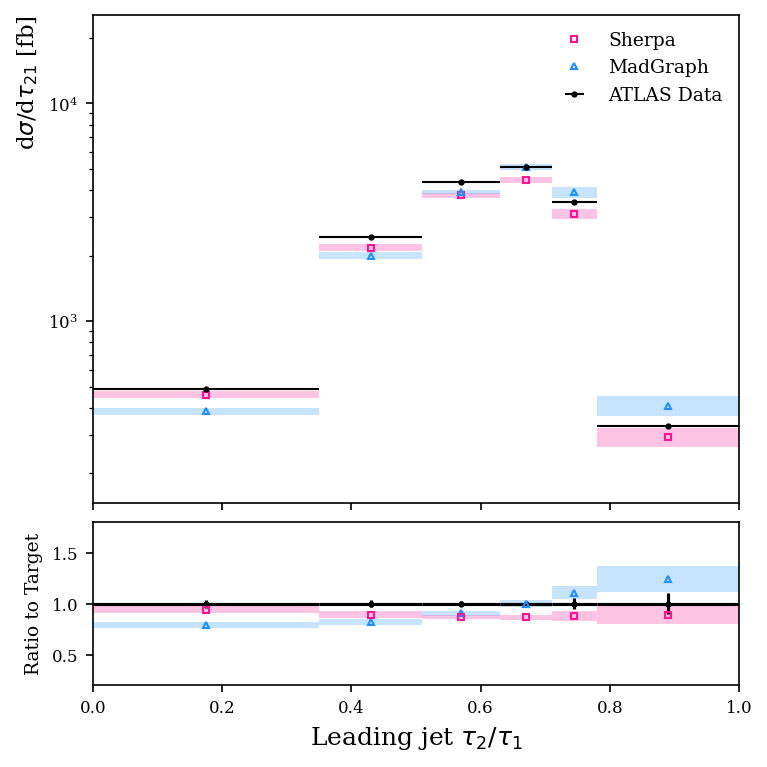

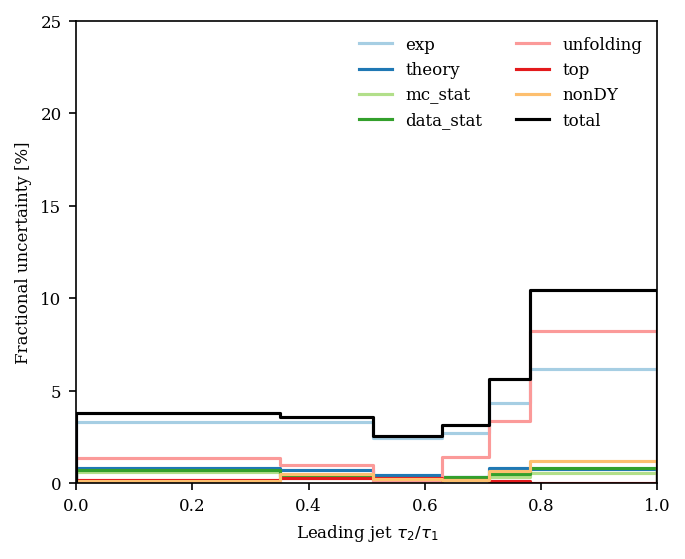

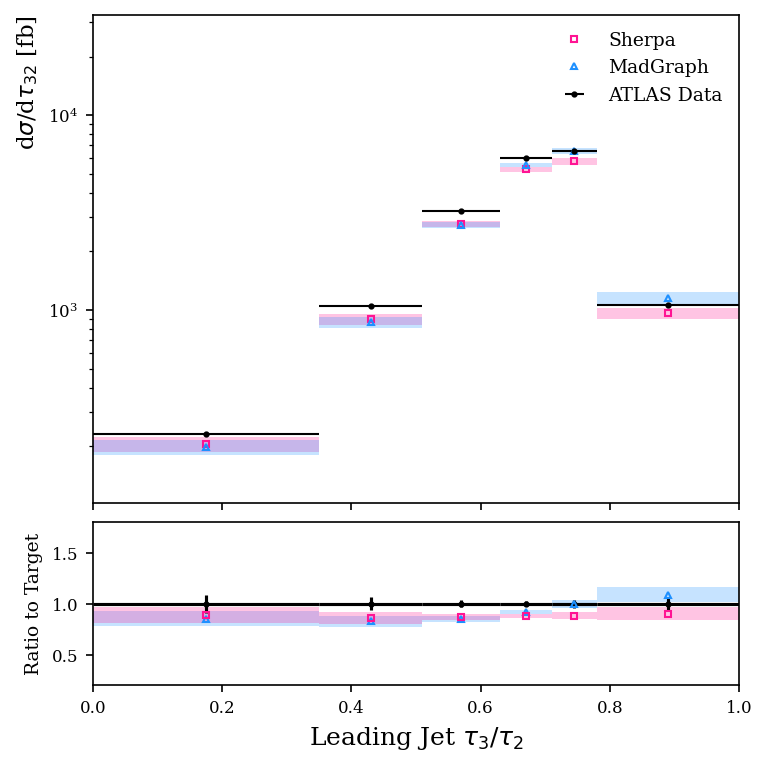

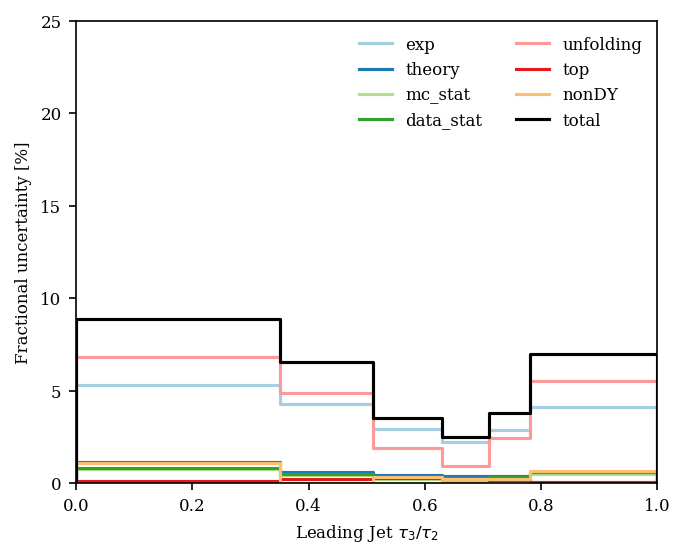

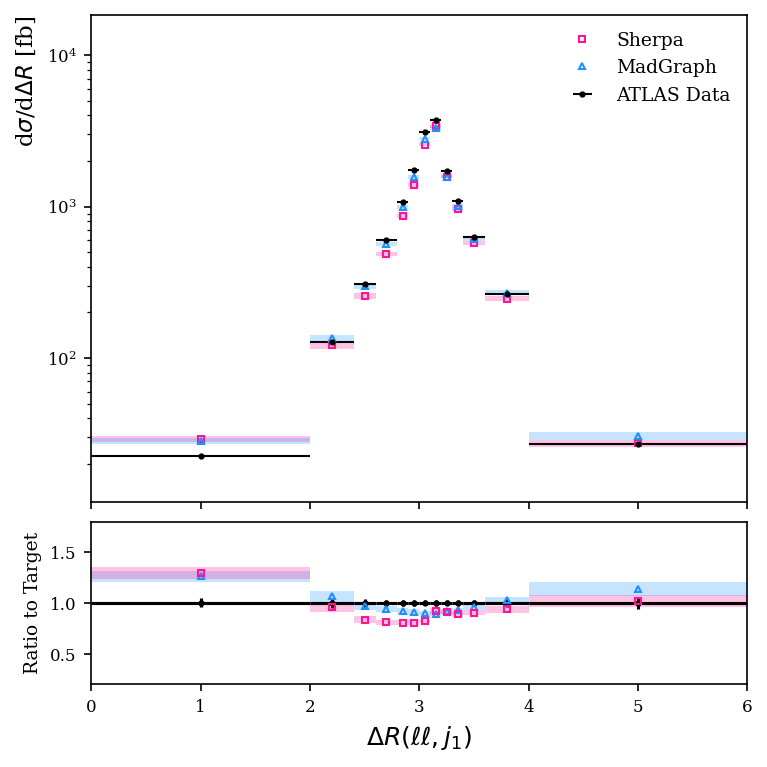

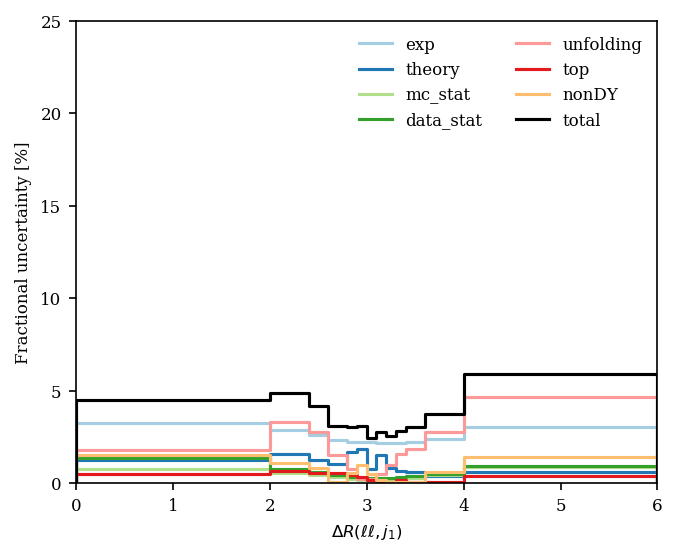

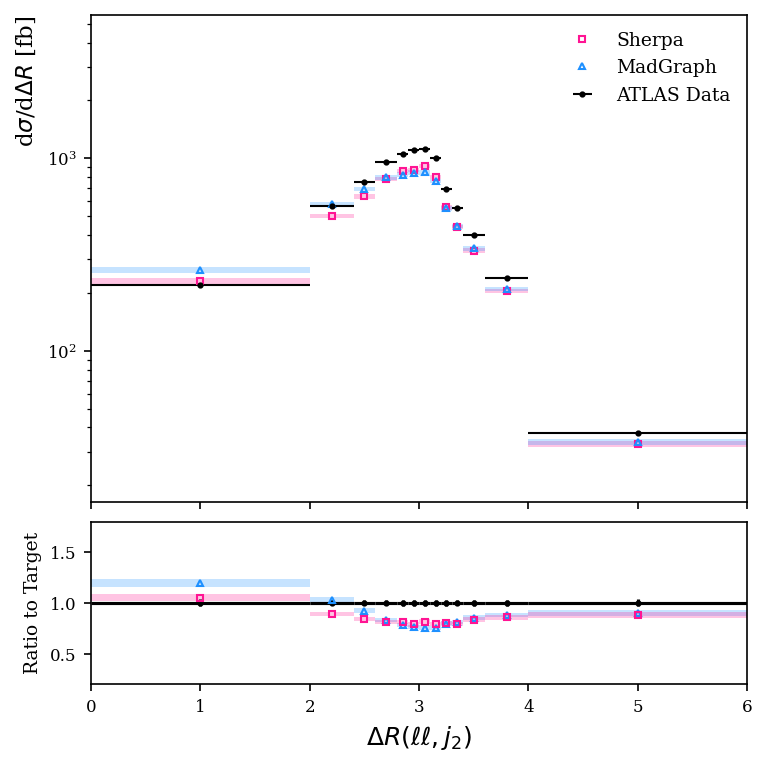

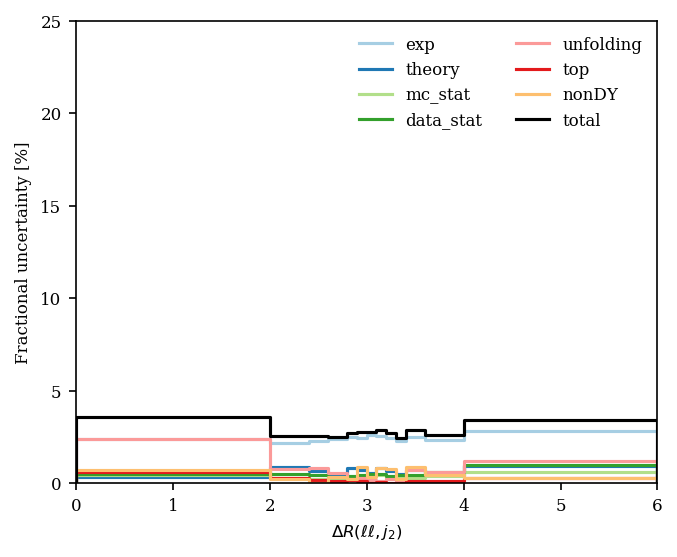

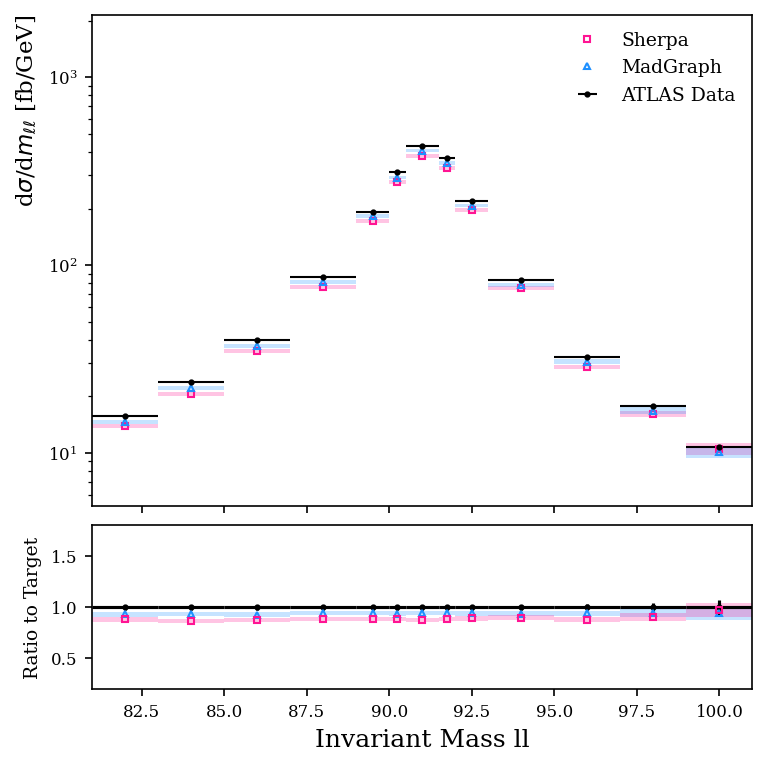

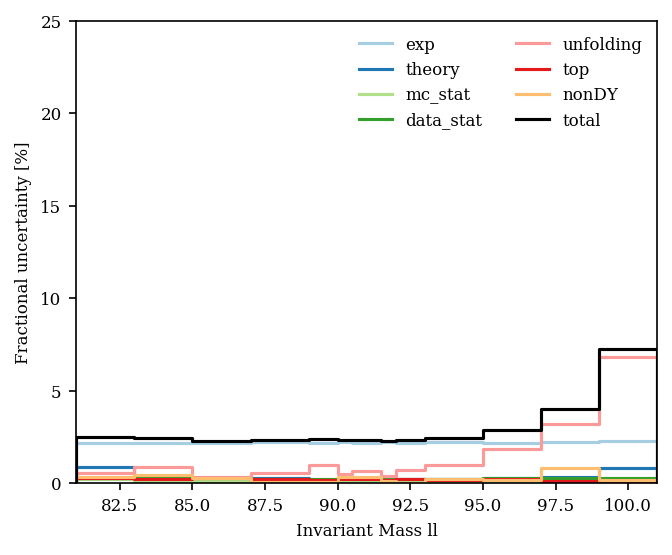

In [27]:
custom_binning("j1tau21", [0.0, 0.35, 0.51, 0.63, 0.71, 0.78, 1.0])
custom_binning("j1tau32", [0.0, 0.35, 0.51, 0.63, 0.71, 0.78, 1.0])
custom_binning("dR_ll1", [0.0, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.6, 4.0, 6.0])
custom_binning("dR_ll2", [0.0, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2, 3.3, 3.4, 3.6, 4.0, 6.0])
custom_binning("m_ll", [81.0, 83.0, 85.0, 87.0, 89.0, 90.0, 90.5, 91.5, 92.0, 93.0, 95.0, 97.0, 99.0, 101.0,])


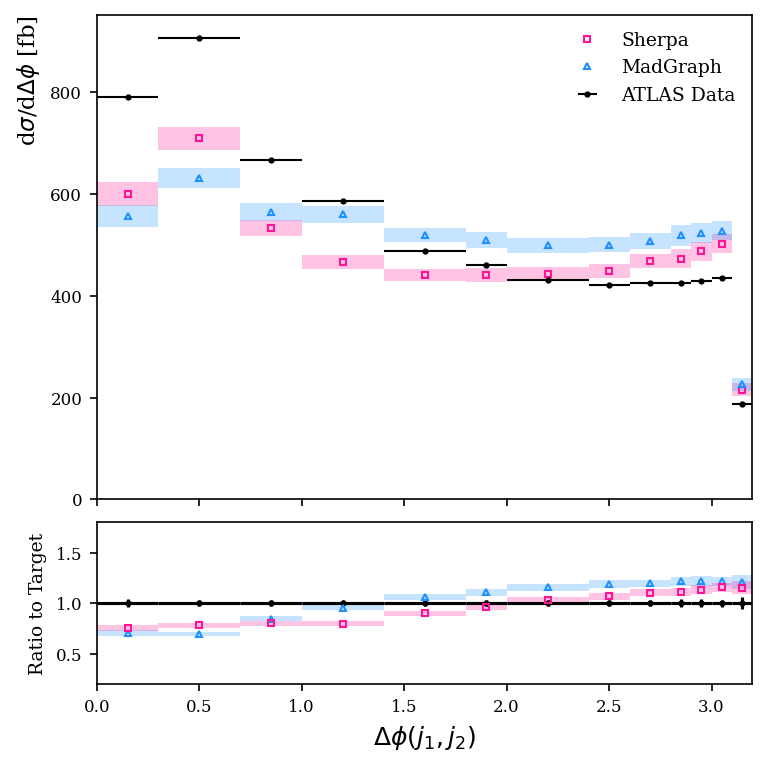

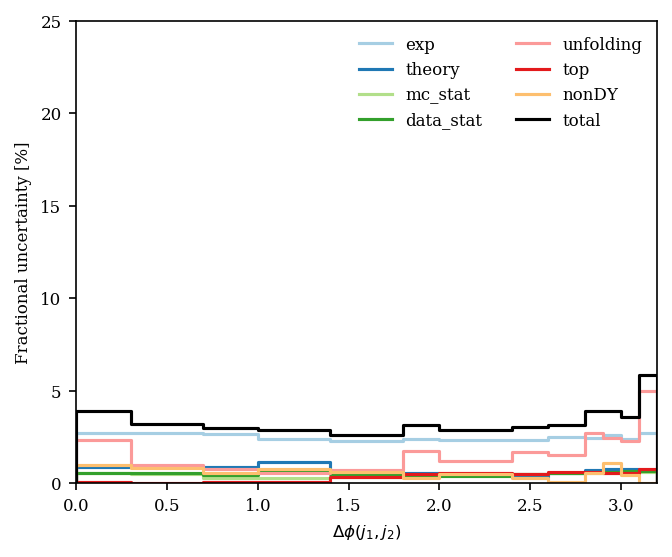

In [23]:
custom_binning("dphi_j1j2", [0.0, 0.3, 0.7, 1.0, 1.4, 1.8, 2.0, 2.4, 2.6, 2.8, 2.9, 3.0, 3.1, 3.2]) 

In [101]:
nom, edges = np.histogram(multifold['m_ll'], bins=[0.0, 50.0, 100.0, 150.0], weights=multifold.weights_nominal)
print(edges)
print(nom)

[  0.  50. 100. 150.]
[   0.        1798.2455      10.0876465]


In [103]:
print([c for c in multifold.columns if 'tau' in c])


['tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'tau21']
